# 03. Pan-Tompkins R-Peak Detection & Heart-Rate Analysis

This notebook details the classical **Pan-Tompkins algorithm** for real-time QRS detection and calculates subsequent heart rate variability (HRV) metrics.

### Pan-Tompkins Algorithm Stages:
1. **Bandpass Filtering (5–15 Hz)**: Isolates energy dominated by the QRS complex.
2. **Five-Point Derivative**: Accentuates the steep slopes of the QRS wave.
3. **Squaring**: Non-linear operator making all points positive and amplifying high slopes.
4. **Moving Window Integration (MWI)**: Accumulates waveform duration (~150 ms).
5. **Dual Adaptive Thresholding**: Distinguishes signal peaks from noise peaks.
6. **Refinement & Refractory Period**: Searches local maximum in filtered ECG, enforcing 200 ms minimum RR spacing.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from src.data_loader import load_record
from src.preprocessing import preprocess_ecg
from src.peak_detection import detect_r_peaks, bandpass_filter, derivative, squaring, moving_window_integration
from src.heart_rate import compute_heart_rate, print_heart_rate_summary
from src import config

## 1. Step-by-Step Transformation of the ECG

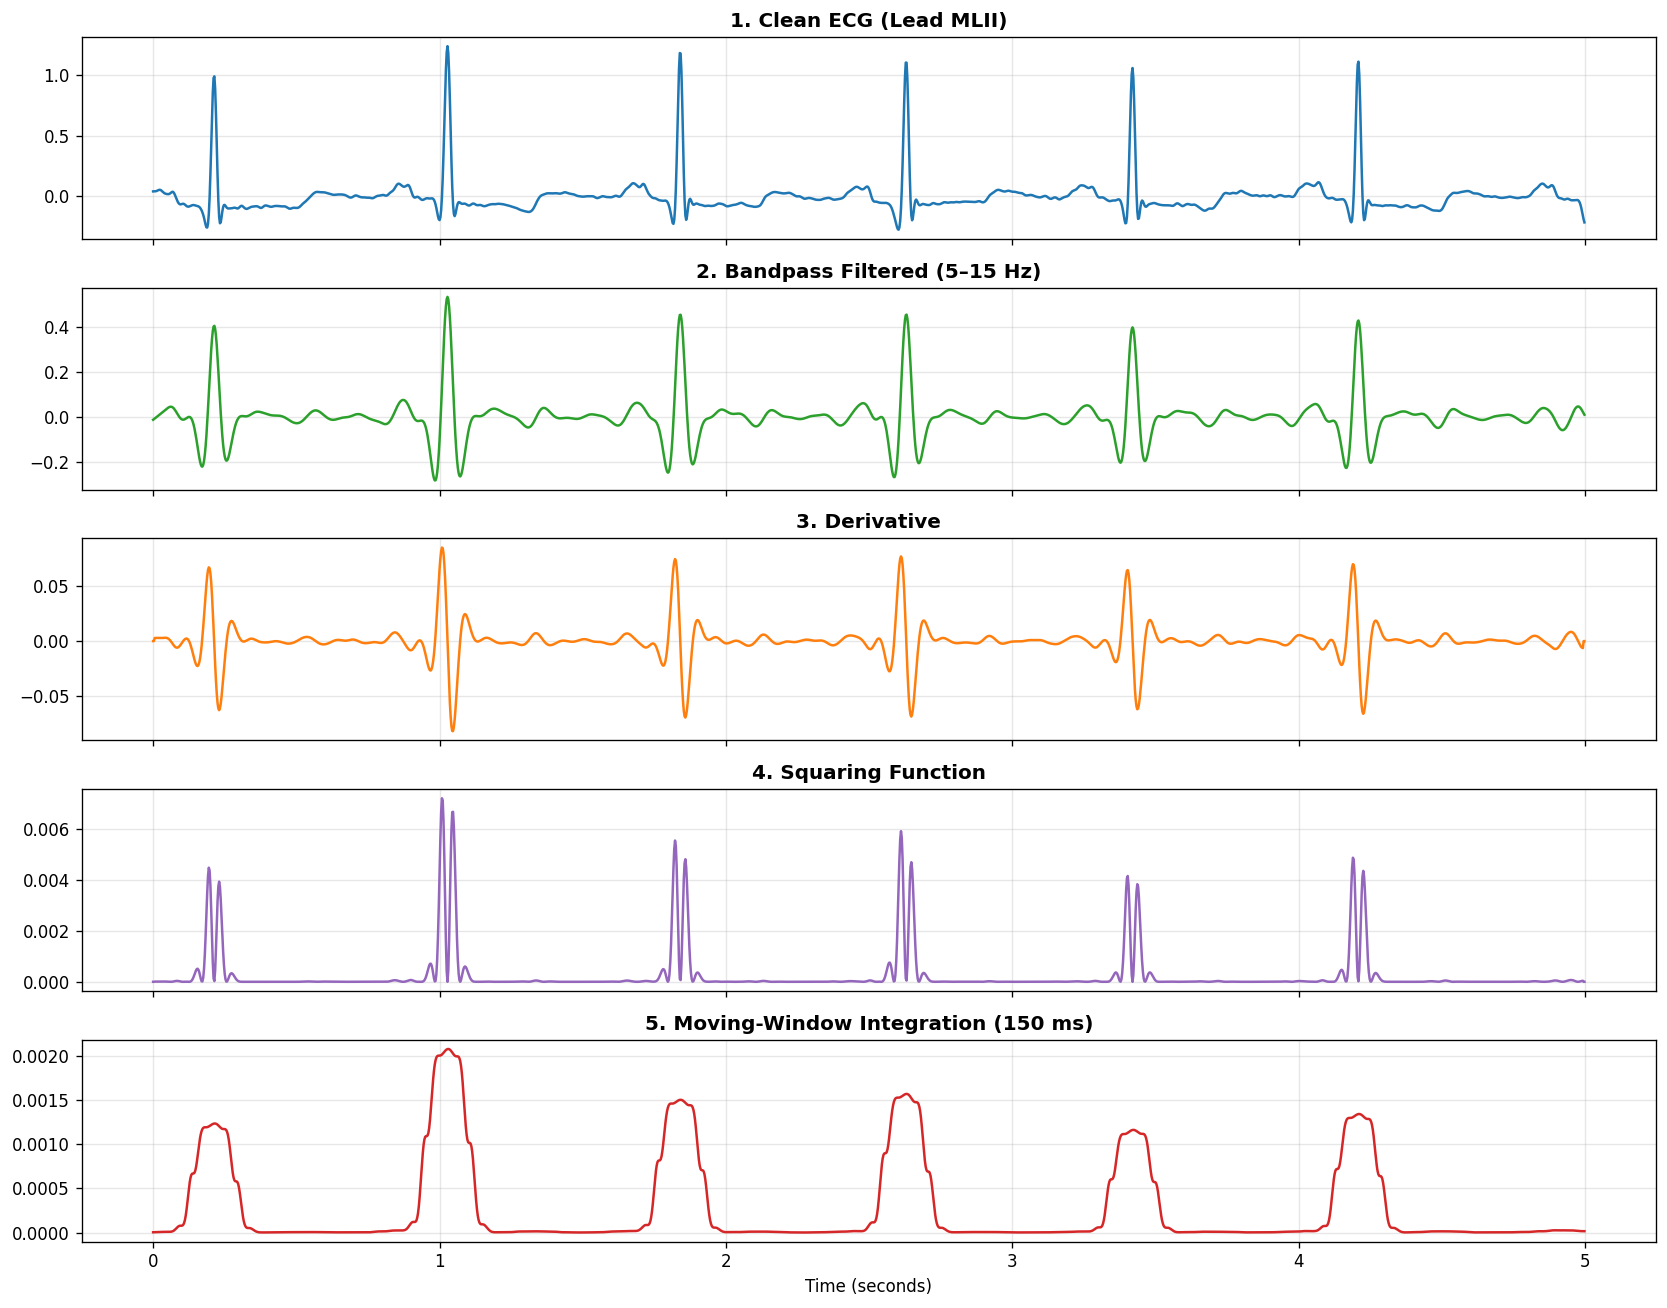

In [2]:
ecg = load_record('100')
fs = ecg.sampling_frequency
ecg_clean = preprocess_ecg(ecg.signal, fs)

# Run intermediate stages on a 5-second slice
idx_slice = slice(0, int(5 * fs))
t_sub = ecg.time[idx_slice]
sig_sub = ecg_clean[idx_slice]

bpass = bandpass_filter(sig_sub, fs, low=5.0, high=15.0)
deriv = derivative(bpass, fs)
sq = squaring(deriv)
mwi = moving_window_integration(sq, fs, window_sec=0.150)

fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True, dpi=120)

axes[0].plot(t_sub, sig_sub, color='#1f77b4')
axes[0].set_title('1. Clean ECG (Lead MLII)', fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_sub, bpass, color='#2ca02c')
axes[1].set_title('2. Bandpass Filtered (5–15 Hz)', fontweight='bold')
axes[1].grid(True, alpha=0.3)

axes[2].plot(t_sub, deriv, color='#ff7f0e')
axes[2].set_title('3. Derivative', fontweight='bold')
axes[2].grid(True, alpha=0.3)

axes[3].plot(t_sub, sq, color='#9467bd')
axes[3].set_title('4. Squaring Function', fontweight='bold')
axes[3].grid(True, alpha=0.3)

axes[4].plot(t_sub, mwi, color='#d62728')
axes[4].set_title('5. Moving-Window Integration (150 ms)', fontweight='bold')
axes[4].set_xlabel('Time (seconds)')
axes[4].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Detect R-Peaks on Full 30-Minute Record

In [3]:
r_peaks = detect_r_peaks(ecg_clean, fs)
print(f'Total R-peaks detected: {len(r_peaks):,}')
print(f'Ground-truth reference beats: {len(ecg.beat_samples):,}')

Total R-peaks detected: 2,265
Ground-truth reference beats: 2,273


## 3. Heart Rate and HRV Analysis

--------------------------------------------------
  Heart Rate Analysis
--------------------------------------------------
  RR intervals     : 2,264
  Mean BPM         : 75.7
  Median BPM       : 75.3
  Min BPM          : 16.0
  Max BPM          : 114.9
  Std BPM          : 5.40
  SDNN             : 84.2 ms
  RMSSD            : 116.3 ms
--------------------------------------------------


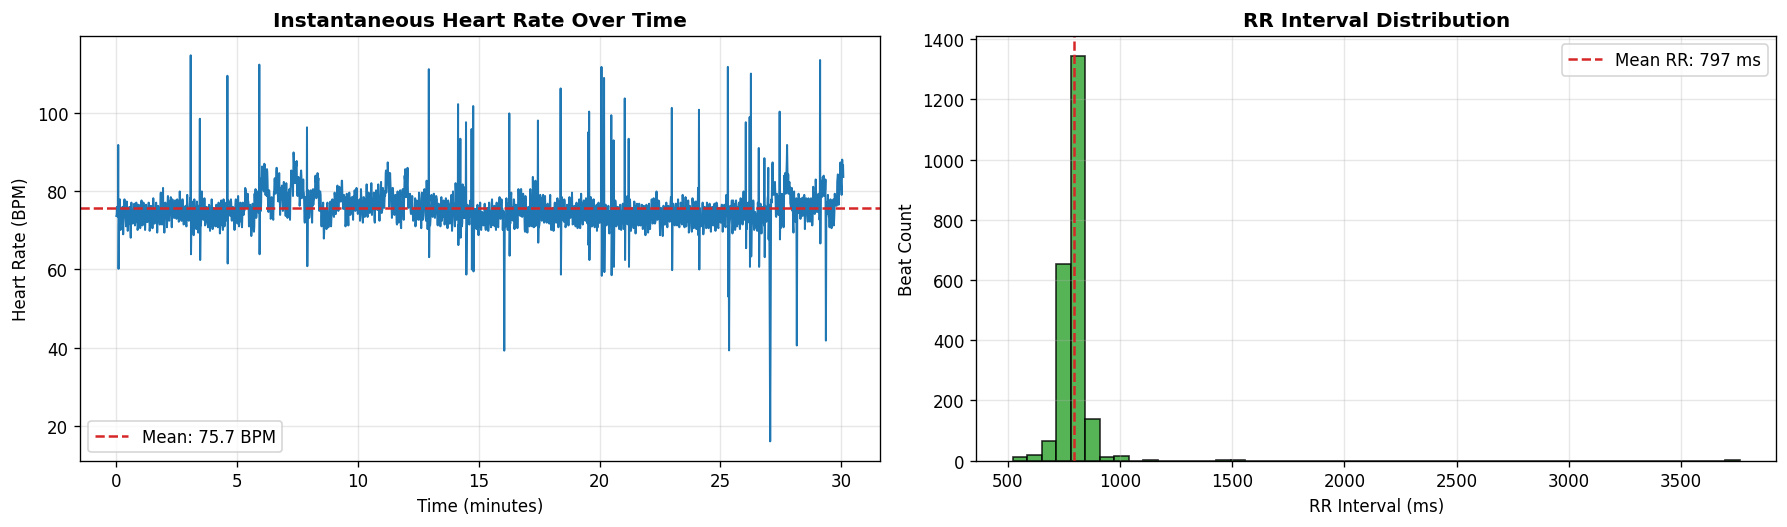

In [4]:
hr_stats = compute_heart_rate(r_peaks, fs)
print_heart_rate_summary(hr_stats)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), dpi=120)

# Heart rate over time
ax1.plot(hr_stats.rr_times / 60, hr_stats.instantaneous_bpm, color='#1f77b4', lw=1.2)
ax1.axhline(hr_stats.mean_bpm, color='#d62728', linestyle='--', label=f'Mean: {hr_stats.mean_bpm:.1f} BPM')
ax1.set_title('Instantaneous Heart Rate Over Time', fontweight='bold')
ax1.set_xlabel('Time (minutes)')
ax1.set_ylabel('Heart Rate (BPM)')
ax1.grid(True, alpha=0.3)
ax1.legend()

# RR interval histogram
ax2.hist(hr_stats.rr_intervals * 1000, bins=50, color='#2ca02c', edgecolor='black', alpha=0.8)
ax2.axvline(np.mean(hr_stats.rr_intervals) * 1000, color='#d62728', linestyle='--', label=f'Mean RR: {np.mean(hr_stats.rr_intervals)*1000:.0f} ms')
ax2.set_title('RR Interval Distribution', fontweight='bold')
ax2.set_xlabel('RR Interval (ms)')
ax2.set_ylabel('Beat Count')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()